In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the main tables
orders = pd.read_csv("/Users/parthsrivastava/Desktop/Project/olist_orders_dataset.csv")
customers = pd.read_csv("/Users/parthsrivastava/Desktop/Project/olist_customers_dataset.csv")
order_items = pd.read_csv("/Users/parthsrivastava/Desktop/Project/olist_order_items_dataset.csv")
payments = pd.read_csv("/Users/parthsrivastava/Desktop/Project/olist_order_payments_dataset.csv")

In [5]:
merge_df = pd.merge(orders, customers, on="customer_id", how="inner")#merging orders on customer using customer_id
merge_df = pd.merge(merge_df, order_items, on="order_id", how="inner")#merging the above df with order_items using order_id
merge_df = pd.merge(merge_df, payments, on="order_id", how="inner")#merging the above df with payments using order_id
print("--- Missing Values Count ---")
print(merge_df.isnull().sum())
merge_df.head()#shows only the first 5 rows of the merged dataframe

--- Missing Values Count ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1245
order_delivered_customer_date    2567
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
payment_sequential                  0
payment_type                        0
payment_installments                0
payment_value                       0
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,1,credit_card,1,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,3,voucher,1,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,2,voucher,1,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,1,boleto,1,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,1,credit_card,3,179.12


In [6]:
print("--- Missing Values Before Cleaning ---")#checking for missing values in the merged dataframe
print(merge_df.isnull().sum())#printing the count of missing values in each column

#If review comments or optional text columns has missing values hain, then fill them with a default value like 'No Review' or 'No Title' so that the data remains consistent and doesn't get corrupted.
if 'review_comment_message' in merge_df.columns:
    merge_df['review_comment_message'].fillna('No Review', inplace=True)

if 'review_comment_title' in merge_df.columns:
    merge_df['review_comment_title'].fillna('No Title', inplace=True)

# If any critical column's data(like order_id or customer_id) is missing, then we should remove that row from the dataset because without those IDs, the data is not useful for analysis.
merge_df.dropna(subset=['order_id', 'customer_id'], inplace=True)

# To see if the missing values have been dealt with or not. If not, then we can take further action.
print("\n--- Missing Values After Cleaning ---")
print(merge_df.isnull().sum())

--- Missing Values Before Cleaning ---
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1245
order_delivered_customer_date    2567
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
payment_sequential                  0
payment_type                        0
payment_installments                0
payment_value                       0
dtype: int64

--- Missing Values After Cleaning ---
order_id                            0
customer_id                        

In [7]:
# 1. Reviews table ko load karein
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

# 2. Master DataFrame ke sath reviews ko merge karein
merge_df = pd.merge(merge_df, reviews, on="order_id", how="inner")

# 3. Ab check karein ki reviews ke andar kitni missing values hain
print("--- Missing Values after merging Reviews ---")
print(merge_df[['review_score', 'review_comment_message']].isnull().sum())

# 4. Agar review comments mein missing values hain, toh unhe fill kar dein
merge_df['review_comment_message'].fillna('No Review', inplace=True)

print("\nMissing values cleaned successfully!")
print("New shape of merge_df:", merge_df.shape)

--- Missing Values after merging Reviews ---
review_score                  0
review_comment_message    67650
dtype: int64

Missing values cleaned successfully!
New shape of merge_df: (117329, 28)


/var/folders/w4/wfc9yv8j72964q9mbhvq9f0h0000gn/T/ipykernel_60189/349231334.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merge_df['review_comment_message'].fillna('No Review', inplace=True)


--- Average Delivery Delay (in days) per Review Score ---
   review_score  delivery_delay_days
0             1            -6.003430
1             2            -9.748141
2             3           -11.114301
3             4           -12.468533
4             5           -13.443437


/var/folders/w4/wfc9yv8j72964q9mbhvq9f0h0000gn/T/ipykernel_60189/2933138067.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='review_score', y='delivery_delay_days', data=delay_vs_review, palette='viridis')


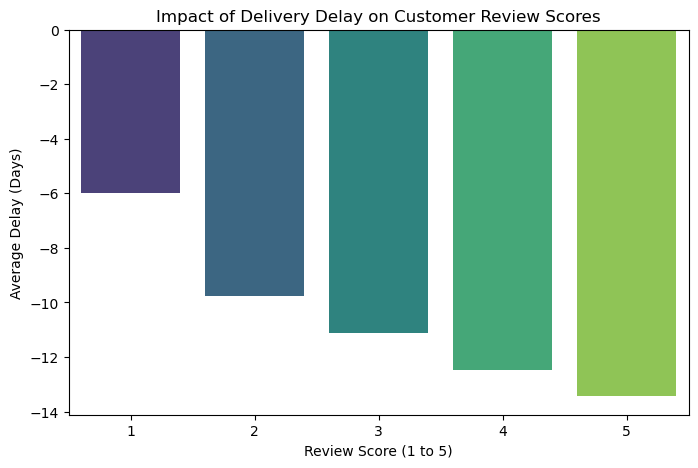

In [8]:
# converting the date columns to datetime format for further analysis
merge_df['order_delivered_customer_date'] = pd.to_datetime(merge_df['order_delivered_customer_date'])
merge_df['order_estimated_delivery_date'] = pd.to_datetime(merge_df['order_estimated_delivery_date'])

# Calculating the delivery delay in days by subtracting the estimated delivery date from the actual delivery date
# If the order was delivered earlier than estimated, the delay will be negative, indicating early delivery. If it was delivered later, the delay will be positive, indicating a late delivery.
merge_df['delivery_delay_days'] = (merge_df['order_delivered_customer_date'] - merge_df['order_estimated_delivery_date']).dt.days

# checking the delivery delay days according to the review score to see if there's any correlation between delivery delay and customer satisfaction
delay_vs_review = merge_df.groupby('review_score')['delivery_delay_days'].mean().reset_index()

print("--- Average Delivery Delay (in days) per Review Score ---")
print(delay_vs_review)

# Drawing Bar Plot 
plt.figure(figsize=(8, 5))
sns.barplot(x='review_score', y='delivery_delay_days', data=delay_vs_review, palette='viridis')
plt.title('Impact of Delivery Delay on Customer Review Scores')
plt.xlabel('Review Score (1 to 5)')
plt.ylabel('Average Delay (Days)')
plt.show()

--- Top 10 States by Revenue ---
   customer_state  total_order_value
25             SP         6195448.33
18             RJ         2212812.93
10             MG         1910900.31
22             RS          931095.64
17             PR          828983.66
4              BA          644329.90
23             SC          621830.41
6              DF          366361.29
8              GO          364539.61
15             PE          331642.80


/var/folders/w4/wfc9yv8j72964q9mbhvq9f0h0000gn/T/ipykernel_58468/4197940476.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_state', y='total_order_value', data=top_states, palette='magma')


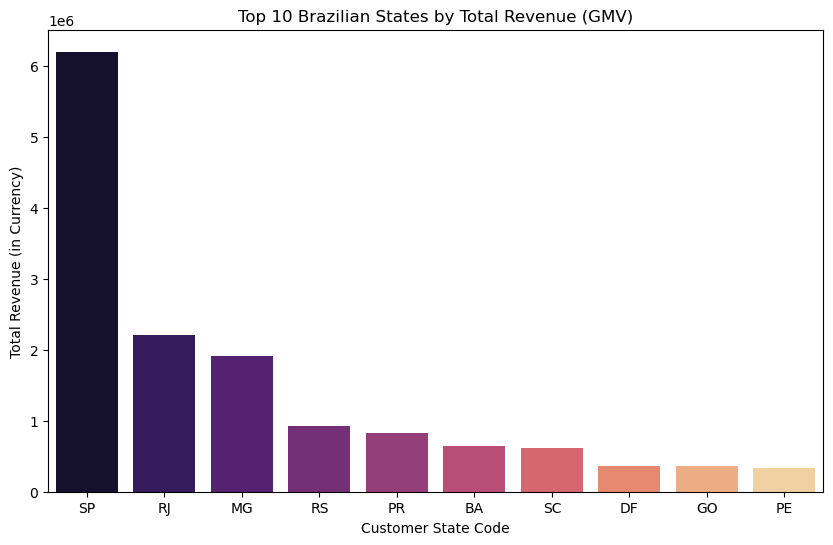

In [15]:
# calculating the total order value (Product Price + Shipping/Freight Cost)
merge_df['total_order_value'] = merge_df['price'] + merge_df['freight_value']

# grouping the data by customer state and summing up the total order value to get the revenue per state
state_revenue = merge_df.groupby('customer_state')['total_order_value'].sum().reset_index()

# Arranging the states in descending order of revenue and selecting the top 10 states
top_states = state_revenue.sort_values(by='total_order_value', ascending=False).head(10)

print("--- Top 10 States by Revenue ---")
print(top_states)

# Bar Plot for Top 10 States by Revenue
plt.figure(figsize=(10, 6))
sns.barplot(x='customer_state', y='total_order_value', data=top_states, palette='magma')
plt.title('Top 10 Brazilian States by Total Revenue (GMV)')
plt.xlabel('Customer State Code')
plt.ylabel('Total Revenue (in Currency)')
plt.xticks(rotation=0)
plt.show()